<a href="https://colab.research.google.com/github/alfredo170987/Proyecto-2-Sistemas-de-Comunicaci-n/blob/main/Notebook_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Asignación Óptima de Potencia en Redes Inalámbricas con PyTorch (Deep Learning)

**Objetivo de la presentación:** Demostrar cómo una **Red Neuronal Artificial construida en PyTorch** aprende a gestionar la potencia de transmisión en un entorno multiusuario con interferencia, logrando un desempeño cercano al óptimo matemático en fracciones de milisegundo (requisito crítico para redes **5G y 6G**). Además, los datos de entrenamiento de la ANN son creados a partir de un modelo matemático.

### Librerías y generación del escenario
Se simulará **3 pares de transmisor-receptor** que comparten la misma banda de frecuencia y se interfieren mutuamente. Se generan 2,000 realizaciones aleatorias del canal inalámbrico siguiendo un modelo de desvanecimiento Rayleigh (distribución exponencial para la ganancia de potencia $|H|^2$).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# Configuración de reproducibilidad
np.random.seed(42)
torch.manual_seed(42)

# Selección automática de dispositivo (GPU si está disponible, si no CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Ejecutando PyTorch en: {device}")

# Hiper parámetros
NUM_USUARIOS = 3
NUM_MUESTRAS = 2000
P_MAX = 1.0       # Potencia máxima permitida por transmisor (1 Watt)
RUIDO = 0.01      # Ruido térmico
DLG = 2.5         # Ganancia de un enlace directo entre un transmisor y un receptor

# Matrices de ganancia de canal |H|^2 de tamaño (NUM_MUESTRAS, NUM_USUARIOS, NUM_USUARIOS) -> (2000, 3, 3)
# H[m, i, j] = ganancia desde el transmisor j hacia el receptor i en el escenario m
#Filas -> receptores
#Columnas -> transmisores
H_dataset = np.random.exponential(scale=1.0, size=(NUM_MUESTRAS, NUM_USUARIOS, NUM_USUARIOS))

# Los enlaces directos (donde i=j) tienen mayor ganancia que las interferencias cruzadas
for i in range(NUM_USUARIOS):
    H_dataset[:, i, i] *= DLG

print(f"Dataset generado: {NUM_MUESTRAS} estados de canal para una red de {NUM_USUARIOS} usuarios con forma {H_dataset.shape}")


Ejecutando PyTorch en: cpu
Dataset generado: 2000 estados de canal para una red de 3 usuarios con forma (2000, 3, 3)


### Cálculo de la tasa suma (Shannon) y datos de entrenamiento: Se utiliza un modelo matemático para generar datos de entrenamiento sintéticos
Se define la capacidad total del sistema (*Sum-Rate*) usando la ecuación de Shannon:
$$R_{total} = \sum_{i=1}^{N} \log_2\left(1 + \frac{H_{i,i} P_i}{\sum_{j \neq i} H_{i,j} P_j + \sigma^2}\right)$$

* $N$= 3 usuarios
* $P_i​$ = potencia del usuario i
* $H_{ii}$ = canal directo
* $H_{ij}$ = interferencia
* $σ^2$ = ruido térmico

Se calcula la combinación óptima de potencias para cada escenario y se convierten los datos a tensores de PyTorch para entrenamiento y validación.


In [2]:
# Calcula la capacidad total (bps/Hz) considerando interferencia mutua.
def calcular_sum_rate(H, potencias):

    sum_rate = 0.0
    for i in range(NUM_USUARIOS):
        senal_deseada = H[i, i] * potencias[i]
        interferencia = sum(H[i, j] * potencias[j] for j in range(NUM_USUARIOS) if j != i)
        sinr = senal_deseada / (interferencia + RUIDO)
        sum_rate += np.log2(1 + sinr)
    return sum_rate

# Generación de etiquetas óptimas (algoritmo de referencia)
candidatos_p = np.linspace(0.0, P_MAX, 11)  #Se usan 11 niveles discretos de potencia (0.0 W a 1.0 W)
combinaciones = np.array(np.meshgrid(candidatos_p, candidatos_p, candidatos_p)).T.reshape(-1, NUM_USUARIOS) # Todas las posibles combinaciones de potencias

X = [] # Entradas: Matriz de ganancias H aplanada (9 valores)
Y = [] # Salidas: Vector de potencias óptimas [P1, P2, P3]

# Se emplea una estrategia de búsqueda exhaustiva (Brute Force Search). Se prueban los 2000 muestras de canal contra todas las posibles combinaciones de potencias (11^3 = 1331).
for m in range(NUM_MUESTRAS):
    H_actual = H_dataset[m]
    tasas = [calcular_sum_rate(H_actual, p) for p in combinaciones]
    mejor_p = combinaciones[np.argmax(tasas)]
    X.append(H_actual.flatten())  # Se añade una entrada
    Y.append(mejor_p)             # Se añade una etiqueta

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

# División en entrenamiento (80%) y prueba (20%)
X_train, X_test, Y_train, Y_test, H_train, H_test = train_test_split(
    X, Y, H_dataset, test_size=0.2, random_state=42
)

# Conversión a Tensores de PyTorch
X_train_t = torch.tensor(X_train)
Y_train_t = torch.tensor(Y_train)
X_test_t = torch.tensor(X_test).to(device)
Y_test_t = torch.tensor(Y_test).to(device)

# DataLoader para entrenamiento por lotes (Mini-batches)
train_dataset = TensorDataset(X_train_t, Y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

print(f"Tensores listos. Muestras de entrenamiento: {len(X_train)}, Muestras de prueba: {len(X_test)}")

Tensores listos. Muestras de entrenamiento: 1600, Muestras de prueba: 400


### Arquitectura de la red neuronal en PyTorch y entrenamiento
Se crea una clase heredando de `nn.Module`. Un detalle clave en ingeniería de telecomunicaciones es usar una función de activación **`Sigmoid()`** en la capa de salida multiplicada por `P_MAX`: esto garantiza matemáticamente que la red **nunca sobrepase los límites físicos de potencia** ($0 \le P_i \le P_{max}$).

In [3]:
# Definición de la red neuronal para asignación de potencia
class AsignacionPotenciaANN(nn.Module): 
    def __init__(self, num_usuarios, p_max):
        super().__init__()
        self.p_max = p_max  # Potencia máxima permitida por transmisor
        self.red = nn.Sequential(
            nn.Linear(num_usuarios ** 2, 64),
            nn.ReLU(),  
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_usuarios),
            nn.Sigmoid()  # Restringe la salida entre 0 y 1
        )

    def forward(self, x):
        return self.red(x) * self.p_max  # Escala la salida al rango [0, P_MAX]

# Instanciar el modelo, función de pérdida y optimizador
modelo = AsignacionPotenciaANN(NUM_USUARIOS, P_MAX).to(device)
criterio = nn.MSELoss()                                        # Función de pérdida: Error cuadrático medio (MSE)
optimizador = optim.Adam(modelo.parameters(), lr=0.005)        # Optimizador: Adam con tasa de aprendizaje de 0.005

EPOCAS = 150
historial_loss = []

print("Iniciando entrenamiento de la red neuronal...")
for epoca in range(EPOCAS):
    modelo.train()
    perdida_epoca = 0.0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizador.zero_grad()                 # 1. Reiniciar gradientes
        predicciones = modelo(batch_x)          # 2. Propagación hacia adelante (Forward)
        loss = criterio(predicciones, batch_y)  # 3. Calcular error
        loss.backward()                         # 4. Retropropagación (Backpropagation)
        optimizador.step()                      # 5. Actualizar pesos

        perdida_epoca += loss.item() * batch_x.size(0)

    historial_loss.append(perdida_epoca / len(train_dataset))

print(f"Entrenamiento finalizado. Error MSE final: {historial_loss[-1]:.4f}")

Iniciando entrenamiento de la red neuronal...
Entrenamiento finalizado. Error MSE final: 0.0406


### Evaluación y Gráficas Comparativas
Se compara la capacidad total obtenida por:
* ANN 
* Optimo teórico
* Potencia máxima fija
* Asignación aleatoria.

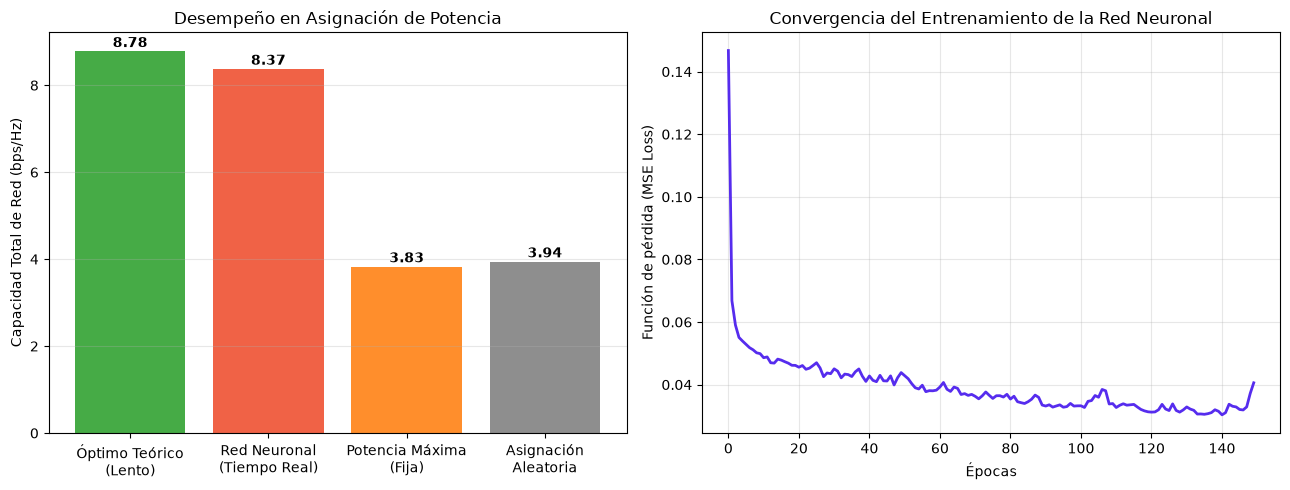

La red neuronal artificial alcanza el 95.4% del rendimiento óptimo teórico.


In [4]:
modelo.eval()
with torch.no_grad():
    Y_pred = modelo(X_test_t).cpu().numpy()

tasas_optimo = []
tasas_ANN = []
tasas_max_potencia = []
tasas_aleatorio = []

for i in range(len(H_test)):
    H_i = H_test[i]
    tasas_optimo.append(calcular_sum_rate(H_i, Y_test[i]))
    tasas_ANN.append(calcular_sum_rate(H_i, Y_pred[i]))
    tasas_max_potencia.append(calcular_sum_rate(H_i, [P_MAX]*NUM_USUARIOS))
    tasas_aleatorio.append(calcular_sum_rate(H_i, np.random.uniform(0, P_MAX, NUM_USUARIOS)))

metodos = ['Óptimo Teórico\n(Lento)', 'Red Neuronal\n(Tiempo Real)', 'Potencia Máxima\n(Fija)', 'Asignación\nAleatoria']
promedios = [np.mean(tasas_optimo), np.mean(tasas_ANN), np.mean(tasas_max_potencia), np.mean(tasas_aleatorio)]
colores = ['#2ca02c', '#ee4c2c', '#ff7f0e', '#7f7f7f']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfica 1: Capacidad Promedio
barras = ax1.bar(metodos, promedios, color=colores, alpha=0.88)
ax1.set_ylabel('Capacidad Total de Red (bps/Hz)')
ax1.set_title('Desempeño en Asignación de Potencia')
ax1.grid(axis='y', alpha=0.3)

for barra in barras:
    yval = barra.get_height()
    ax1.text(barra.get_x() + barra.get_width()/2, yval + 0.1, f"{yval:.2f}", ha='center', fontweight='bold')

# Gráfica 2: Curva de Aprendizaje (Loss)
ax2.plot(historial_loss, color="#562cee", linewidth=2)
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Función de pérdida (MSE Loss)')
ax2.set_title('Convergencia del Entrenamiento de la Red Neuronal')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

eficiencia_relativa = (np.mean(tasas_ANN) / np.mean(tasas_optimo)) * 100
print(f"La red neuronal artificial alcanza el {eficiencia_relativa:.1f}% del rendimiento óptimo teórico.")

### Comparación de Latencia en Tiempo Real (5G / 6G)
Se mide el tiempo de ejecución en milisegundos (ms) para demostrar que la ANN cumple con el requisito de **1 ms** del estándar 5G NR, mientras que la optimización tradicional excede ese límite.

 Tiempo por decisión (Optimización Clásica): 7.0790 ms
 Tiempo por decisión (Inferencia PyTorch):   0.000396 ms
 La ANN es 17,865 veces más rápido.


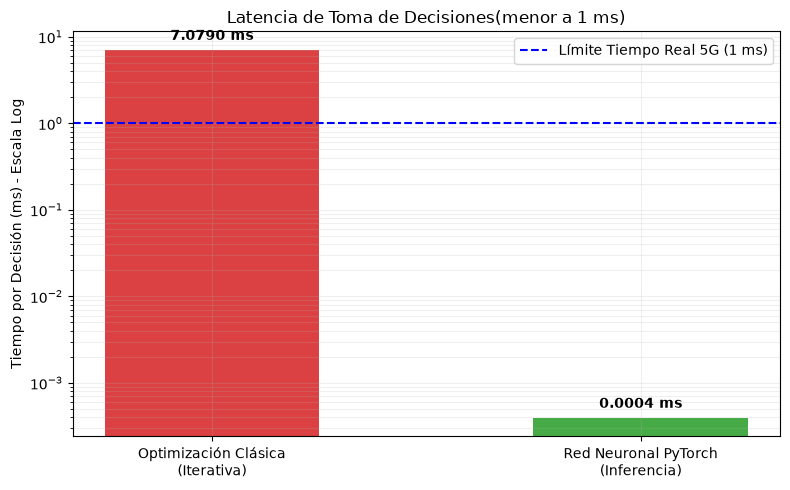

In [9]:
# 1. Tiempo de Optimización Tradicional
inicio_trad = time.perf_counter()
for m in range(len(H_test)):
    H_actual = H_test[m]
    tasas = [calcular_sum_rate(H_actual, p) for p in combinaciones]
    _ = combinaciones[np.argmax(tasas)]
tiempo_por_modelo_mat = ((time.perf_counter() - inicio_trad) * 1000) / len(H_test)

# 2. Tiempo de la red neuronal artificial
modelo.eval()
with torch.no_grad():
    _ = modelo(X_test_t)  # Calentamiento inicial (warm-up)
    inicio_pt = time.perf_counter()
    _ = modelo(X_test_t)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    tiempo_por_ANN = ((time.perf_counter() - inicio_pt) * 1000) / len(H_test)

speedup = tiempo_por_modelo_mat / tiempo_por_ANN

print(f" Tiempo por decisión (Optimización Clásica): {tiempo_por_modelo_mat:.4f} ms")
print(f" Tiempo por decisión (Inferencia PyTorch):   {tiempo_por_ANN:.6f} ms")
print(f" La ANN es {speedup:,.0f} veces más rápido.")

# Gráfica de Latencia
fig, ax = plt.subplots(figsize=(8, 5))
metodos_tiempo = ['Optimización Clásica\n(Iterativa)', 'Red Neuronal PyTorch\n(Inferencia)']
tiempos = [tiempo_por_modelo_mat, tiempo_por_ANN]
colores_tiempo = ['#d62728', '#2ca02c']

barras = ax.bar(metodos_tiempo, tiempos, color=colores_tiempo, width=0.5, alpha=0.88)
ax.set_yscale('log')
ax.set_ylabel('Tiempo por Decisión (ms) - Escala Log')
ax.set_title('Latencia de Toma de Decisiones(menor a 1 ms)')
ax.axhline(y=1.0, color='blue', linestyle='--', linewidth=1.5, label='Límite Tiempo Real 5G (1 ms)')
ax.legend()
ax.grid(True, which="both", ls="-", alpha=0.2)

for barra in barras:
    yval = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2, yval * 1.3, f"{yval:.4f} ms", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()